Can machine learning accurately diagnose PCOS using basic clinical signs alone, and what features drive the final diagnosis?

task 1 baseline results
train accuracy: 0.933
test accuracy: 0.882
test roc-auc : 0.94
test f1-score: 0.814


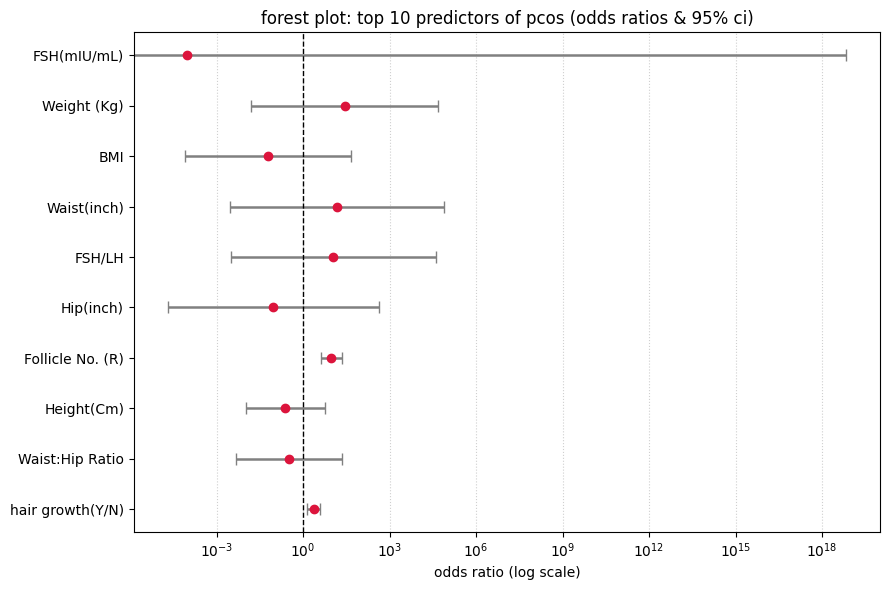

In [ ]:
# import standard libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

#load the dataset
df = pd.read_csv("PCOS_data.csv")

#clean column names
df.columns = df.columns.str.strip()

#patient identifiers
df = df.drop(columns=["Sl. No", "Patient File No."])

#fix the two text entries in numeric columns since it was crashing before; convert text to float!
df["II    beta-HCG(mIU/mL)"] = pd.to_numeric(
    df["II    beta-HCG(mIU/mL)"].astype(str).str.replace("1.99.", "1.99", regex=False),
    errors="coerce",
)
df["AMH(ng/mL)"] = pd.to_numeric(df["AMH(ng/mL)"], errors="coerce")

#fill any missing values with the column median
df = df.fillna(df.median(numeric_only=True))

#task 1: train baseline logistic regression & forest plot

#separate input features and target
x = df.drop(columns=["PCOS (Y/N)"])
y = df["PCOS (Y/N)"]

#split into 75% train and 25% test sets
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42, stratify=y
)

#standardize features so odds ratios are comparable
scaler = StandardScaler()
x_train_scaled = pd.DataFrame(scaler.fit_transform(x_train), columns=x.columns)
x_test_scaled = pd.DataFrame(scaler.transform(x_test), columns=x.columns)

#train logistic regression on all features
model_all = LogisticRegression(max_iter=1000, random_state=42)
model_all.fit(x_train_scaled, y_train)

#evaluate on the training set
train_pred = model_all.predict(x_train_scaled)

#eevaluate on the test set
test_pred = model_all.predict(x_test_scaled)
test_prob = model_all.predict_proba(x_test_scaled)[:, 1]

print("task 1 baseline results")
print("train accuracy:", round(accuracy_score(y_train, train_pred), 3))
print("test accuracy:", round(accuracy_score(y_test, test_pred), 3))
print("test roc-auc :", round(roc_auc_score(y_test, test_prob), 3))
print("test f1-score:", round(f1_score(y_test, test_pred), 3))

#ccalculate odds ratios and confidence intervals using statsmodels
x_sm = sm.add_constant(x_train_scaled)
logit_fit = sm.Logit(y_train.values, x_sm).fit(disp=False)

#build a table with coefficients and odds ratios
forest_df = pd.DataFrame(
    {
        "feature": x.columns,
        "coef": logit_fit.params.values[1:],
        "odds_ratio": np.exp(logit_fit.params.values[1:]),
        "ci_lower": np.exp(logit_fit.conf_int()[0].values[1:]),
        "ci_upper": np.exp(logit_fit.conf_int()[1].values[1:]),
    }
)

# elect the top 10 most influential features by absolute coefficient
top_features = forest_df.reindex(
    forest_df["coef"].abs().sort_values(ascending=True).tail(10).index
)

#plot the forest plot
plt.figure(figsize=(9, 6))
plt.errorbar(
    top_features["odds_ratio"],
    top_features["feature"],
    xerr=[
        top_features["odds_ratio"] - top_features["ci_lower"],
        top_features["ci_upper"] - top_features["odds_ratio"],
    ],
    fmt="o",
    color="crimson",
    ecolor="gray",
    elinewidth=1.8,
    capsize=4,
)
plt.axvline(1.0, color="black", linestyle="--", linewidth=1)
plt.xscale("log")
plt.xlabel("odds ratio (log scale)")
plt.title("forest plot: top 10 predictors of pcos (odds ratios & 95% ci)")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
#task 2: compare models across clinical modalities

#define feature groups based on clinical availability
clinical_lifestyle = [
    "Age (yrs)",
    "Weight (Kg)",
    "Height(Cm)",
    "BMI",
    "Waist:Hip Ratio",
    "Cycle(R/I)",
    "Cycle length(days)",
    "Marraige Status (Yrs)",
    "Pregnant(Y/N)",
    "No. of abortions",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)",
    "BP _Systolic (mmHg)",
    "BP _Diastolic (mmHg)",
]

biochemical_labs = [
    "Hb(g/dl)",
    "Pulse rate(bpm)",
    "RR (breaths/min)",
    "Blood Group",
    "I   beta-HCG(mIU/mL)",
    "II    beta-HCG(mIU/mL)",
    "FSH(mIU/mL)",
    "LH(mIU/mL)",
    "FSH/LH",
    "TSH (mIU/L)",
    "AMH(ng/mL)",
    "PRL(ng/mL)",
    "Vit D3 (ng/mL)",
    "PRG(ng/mL)",
    "RBS(mg/dl)",
]

ultrasound_only = [
    "Follicle No. (L)",
    "Follicle No. (R)",
    "Avg. F size (L) (mm)",
    "Avg. F size (R) (mm)",
    "Endometrium (mm)",
]

rotterdam_core = [
    "Follicle No. (R)",
    "Follicle No. (L)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Cycle(R/I)",
    "Pimples(Y/N)",
    "Cycle length(days)",
    "BMI",
]

#group models to test
modality_models = {
    "all features": list(x.columns),
    "rotterdam core": rotterdam_core,
    "clinical & lifestyle": clinical_lifestyle,
    "ultrasound only": ultrasound_only,
    "biochemical labs": biochemical_labs,
}

#5-fold cross validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison_table = []

for name, feature_list in modality_models.items():
    #subset and scale the features
    modality_scaler = StandardScaler()
    x_sub = df[feature_list]
    x_sub_scaled = modality_scaler.fit_transform(x_sub)

    #train and test set split
    x_tr, x_te, y_tr, y_te = train_test_split(
        x_sub, y, test_size=0.25, random_state=42, stratify=y
    )
    x_tr_scaled = modality_scaler.fit_transform(x_tr)
    x_te_scaled = modality_scaler.transform(x_te)

    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(x_tr_scaled, y_tr)

    train_acc = accuracy_score(y_tr, clf.predict(x_tr_scaled))
    test_acc = accuracy_score(y_te, clf.predict(x_te_scaled))
    test_auc = roc_auc_score(y_te, clf.predict_proba(x_te_scaled)[:, 1])

    #k-fold cross validation
    cv_auc = cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        x_sub_scaled,
        y,
        cv=cv,
        scoring="roc_auc",
    ).mean()
    cv_acc = cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        x_sub_scaled,
        y,
        cv=cv,
        scoring="accuracy",
    ).mean()

    # 3. probabilistic information criteria (aic and bic)
    x_const = sm.add_constant(x_sub_scaled)
    try:
        sm_fit = sm.Logit(y, x_const).fit(disp=False)
        aic_val = round(sm_fit.aic, 2)
        bic_val = round(sm_fit.bic, 2)
    except:
        aic_val = np.nan
        bic_val = np.nan

    #store the metrics
    comparison_table.append(
        {
            "model name": name,
            "num features": len(feature_list),
            "train acc": round(train_acc, 3),
            "test acc": round(test_acc, 3),
            "test auc": round(test_auc, 3),
            "cv auc": round(cv_auc, 3),
            "cv acc": round(cv_acc, 3),
            "aic": aic_val,
            "bic": bic_val,
        }
    )

#print the comparison summary
comparison_df = pd.DataFrame(comparison_table)
print("task 2 modality comparison table")
print(comparison_df.to_string(index=False))

task 2 modality comparison table
          model name  num features  train acc  test acc  test auc  cv auc  cv acc    aic    bic
        all features            41      0.933     0.882     0.940   0.942   0.893 295.96 476.29
      rotterdam core             8      0.904     0.904     0.946   0.951   0.902 280.05 318.69
clinical & lifestyle            19      0.852     0.868     0.896   0.880   0.843 435.98 521.85
     ultrasound only             5      0.857     0.846     0.875   0.894   0.839 408.27 434.03
    biochemical labs            15      0.716     0.669     0.625   0.633   0.678 644.61 713.31


In [ ]:
# calculate odds ratios and 95% confidence intervals
x_sm = sm.add_constant(x_train_scaled)
logit_fit = sm.Logit(y_train.values, x_sm).fit(disp=False)

# build a clean summary table
effects_table = pd.DataFrame(
    {
        "feature": x.columns,
        "coef": logit_model.params.values[1:],
        "odds_ratio": np.exp(logit_model.params.values[1:]),
        "ci_lower": np.exp(logit_model.conf_int()[0].values[1:]),
        "ci_upper": np.exp(logit_model.conf_int()[1].values[1:]),
        "p_value": logit_model.pvalues.values[1:],
    }
)

# sort by absolute effect size to show the strongest predictors first
effects_table["abs_coef"] = effects_table["coef"].abs()
top_effects = effects_table.sort_values(by="abs_coef", ascending=False).drop(
    columns=["abs_coef"]
)

# display top 10 features rounded to 2 decimal places
print(top_effects.head(10).round(2).to_string(index=False))

              feature  coef  odds_ratio  ci_lower  ci_upper  p_value
     Follicle No. (R)  2.23        9.30      4.00     21.63     0.00
     hair growth(Y/N)  0.86        2.36      1.41      3.94     0.00
Marraige Status (Yrs) -0.81        0.44      0.21      0.92     0.03
      Pulse rate(bpm)  0.80        2.22      0.86      5.70     0.10
     Weight gain(Y/N)  0.78        2.19      1.23      3.90     0.01
           Cycle(R/I)  0.77        2.16      1.27      3.67     0.00
 Skin darkening (Y/N)  0.73        2.07      1.25      3.45     0.00
     Follicle No. (L)  0.59        1.80      0.80      4.03     0.15
         Pimples(Y/N)  0.58        1.79      1.09      2.94     0.02
           RBS(mg/dl)  0.50        1.64      1.07      2.52     0.02
